In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

In [2]:
def plot_combined_history(model_configs, metrics=['loss', 'auc', 'acc'], mode='val', save_dir='./comparison_plots'):
    """
    绘制多个模型的训练历史对比曲线 (支持 loss, auc, acc 等)。
    
    Args:
        model_configs (dict): 模型配置字典，包含路径、颜色、线型等。
        metrics (list): 需要画的指标列表，例如 ['loss', 'auc', 'acc', 'bce']。
        mode (str): 'val' (验证集) 或 'train' (训练集)。默认对比验证集效果。
        save_dir (str): 图片保存目录。
    """
    
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)

    # 设置风格 (保持和你 ROC 函数一致)
    sns.set_theme(style="whitegrid", font_scale=1.2)

    # 针对每个指标画一张图 (例如一张图专门对比所有模型的 Loss)
    for metric in metrics:
        plt.figure(figsize=(20, 8)) # 稍微宽一点以便放图例
        
        print(f"{'='*20} Plotting Combined {metric.upper()} ({mode}) {'='*20}")
        
        has_valid_data = False
        
        # 遍历所有模型
        for model_name, config in model_configs.items():
            file_path = config['path']
            
            if not os.path.exists(file_path):
                print(f"[Error] File not found: {file_path}")
                continue
            
            # --- 读取 npy 字典 (参考你的 ROC 函数逻辑) ---
            try:
                # history 结构通常是 {'train': {'loss': [...]}, 'val': {'loss': [...]}}
                history = np.load(file_path, allow_pickle=True).item()
            except Exception as e:
                print(f"[Error] Failed to load {file_path}: {e}")
                continue
            
            # 检查 mode (train/val) 是否存在
            if mode not in history:
                print(f"[Warning] Mode '{mode}' not found in {model_name}")
                continue
                
            # 检查 metric (loss/auc...) 是否存在
            if metric not in history[mode]:
                print(f"[Warning] Metric '{metric}' not found in {model_name} ({mode})")
                continue
            
            # --- 提取数据 ---
            data = history[mode][metric]
            epochs = range(1, len(data) + 1)
            
            # --- 计算最佳值 (用于图例展示) ---
            # 如果是 loss 或 bce，越小越好；如果是 acc 或 auc，越大越好
            if metric in ['loss', 'bce', 'var']:
                best_val = np.min(data)
                best_epoch = np.argmin(data) + 1
                best_str = f"Min: {best_val:.4f} @ Ep{best_epoch}"
            else:
                best_val = np.max(data)
                best_epoch = np.argmax(data) + 1
                best_str = f"Max: {best_val:.4f} @ Ep{best_epoch}"

            has_valid_data = True
            
            # --- 绘图 ---
            plt.plot(
                epochs, data,
                label=f'{model_name} ({best_str})', # 图例包含最佳值
                color=config['color'],
                linestyle=config['style'],
                linewidth=config['linewidth'],
                alpha=0.85
            )
            print(f"Loaded {model_name}: Last {metric}={data[-1]:.4f}, Best={best_val:.4f}")

        if not has_valid_data:
            print(f"No valid data found for metric: {metric}")
            plt.close()
            continue

        # --- 美化图表 ---
        # 标题和轴标签
        mode_str = "Validation" if mode == 'val' else "Training"
        plt.xlabel('Epochs', fontsize=14, fontweight='bold')
        plt.ylabel(f'{metric.upper()}', fontsize=14, fontweight='bold')
        plt.title(f'Ablation Study: {mode_str} {metric.upper()} Comparison', fontsize=16, fontweight='bold', pad=15)
        
        # 坐标轴微调
        # 如果是 AUC 或 ACC，通常固定在 0.5-1.0 之间看比较清晰
        # TB11K
        #if metric in ['auc', 'acc']:
        #    plt.ylim([0.5, 1.02])
        if metric == 'acc':
            plt.ylim([0.4, 1.05])
        if metric == 'auc':
            plt.ylim([0.35, 1.05])
        
        # 图例设置 (放在合适的位置)
        plt.legend(loc="best", fontsize=11, frameon=True, fancybox=True, framealpha=0.9)
        
        # 网格 (你之前的代码是 False，这里保持一致，或者设为 True 看趋势更清楚)
        plt.grid(True, linestyle='--', alpha=0.5) 

        # --- 保存 ---
        save_filename = f"combined_{mode}_{metric}.png"
        save_full_path = os.path.join(save_dir, save_filename)
        plt.savefig(save_full_path, dpi=300, bbox_inches='tight')
        print(f"\nFigure saved to: {save_full_path}\n")
        
        plt.show()

==================== Plotting Combined AUC (val) ====================
Loaded Baseline: Last auc=0.8021, Best=0.8027
Loaded WID: Last auc=0.8086, Best=0.8149
Loaded EDL: Last auc=0.8319, Best=0.8337
Loaded WID+EDL: Last auc=0.8032, Best=0.8204

Figure saved to: ./figures/MIMIC/0216_vgg16/Pneumonia/combined_val_auc.png



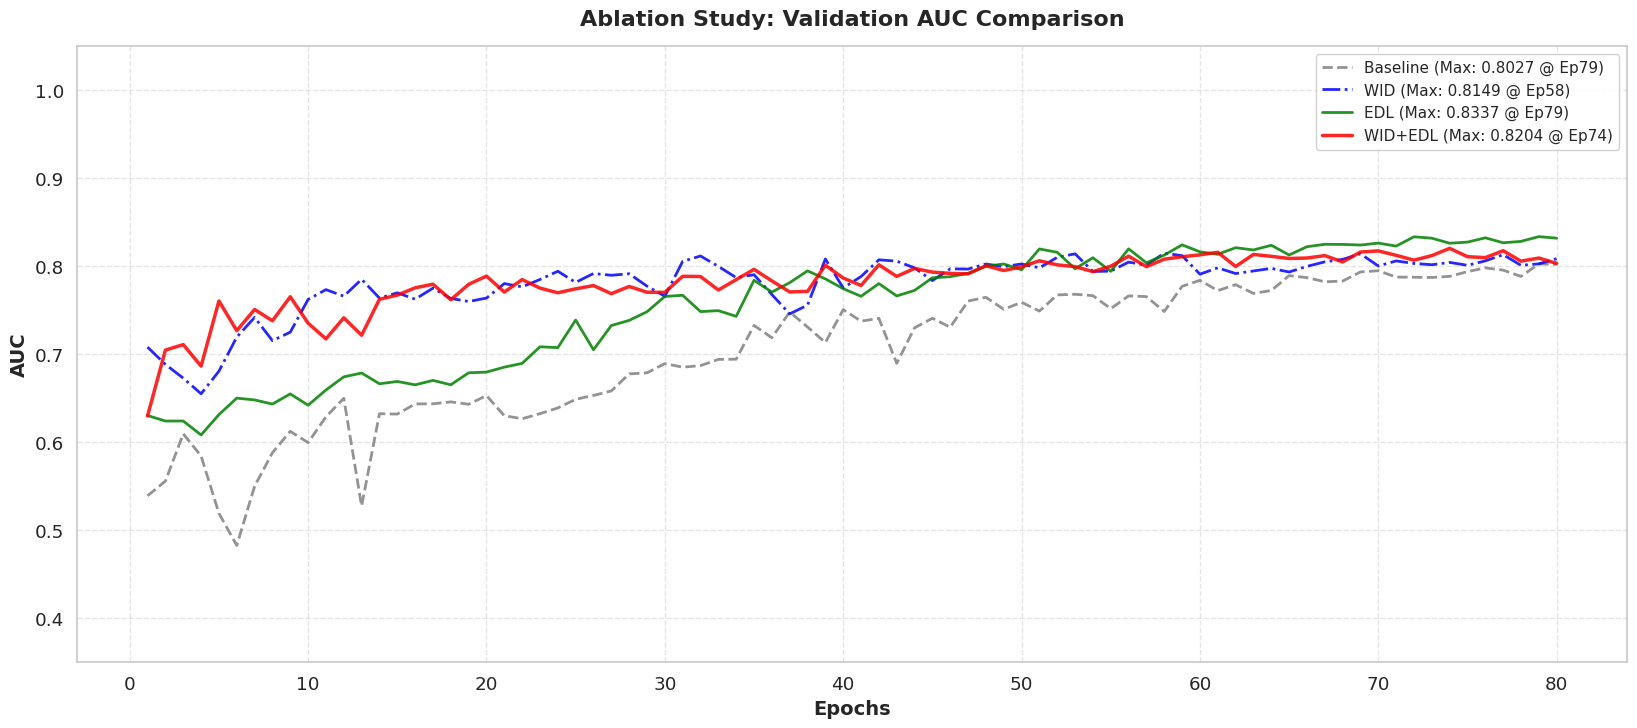

==================== Plotting Combined ACC (val) ====================
Loaded Baseline: Last acc=0.7529, Best=0.7529
Loaded WID: Last acc=0.7608, Best=0.7725
Loaded EDL: Last acc=0.7804, Best=0.7804
Loaded WID+EDL: Last acc=0.7490, Best=0.7804

Figure saved to: ./figures/MIMIC/0216_vgg16/Pneumonia/combined_val_acc.png



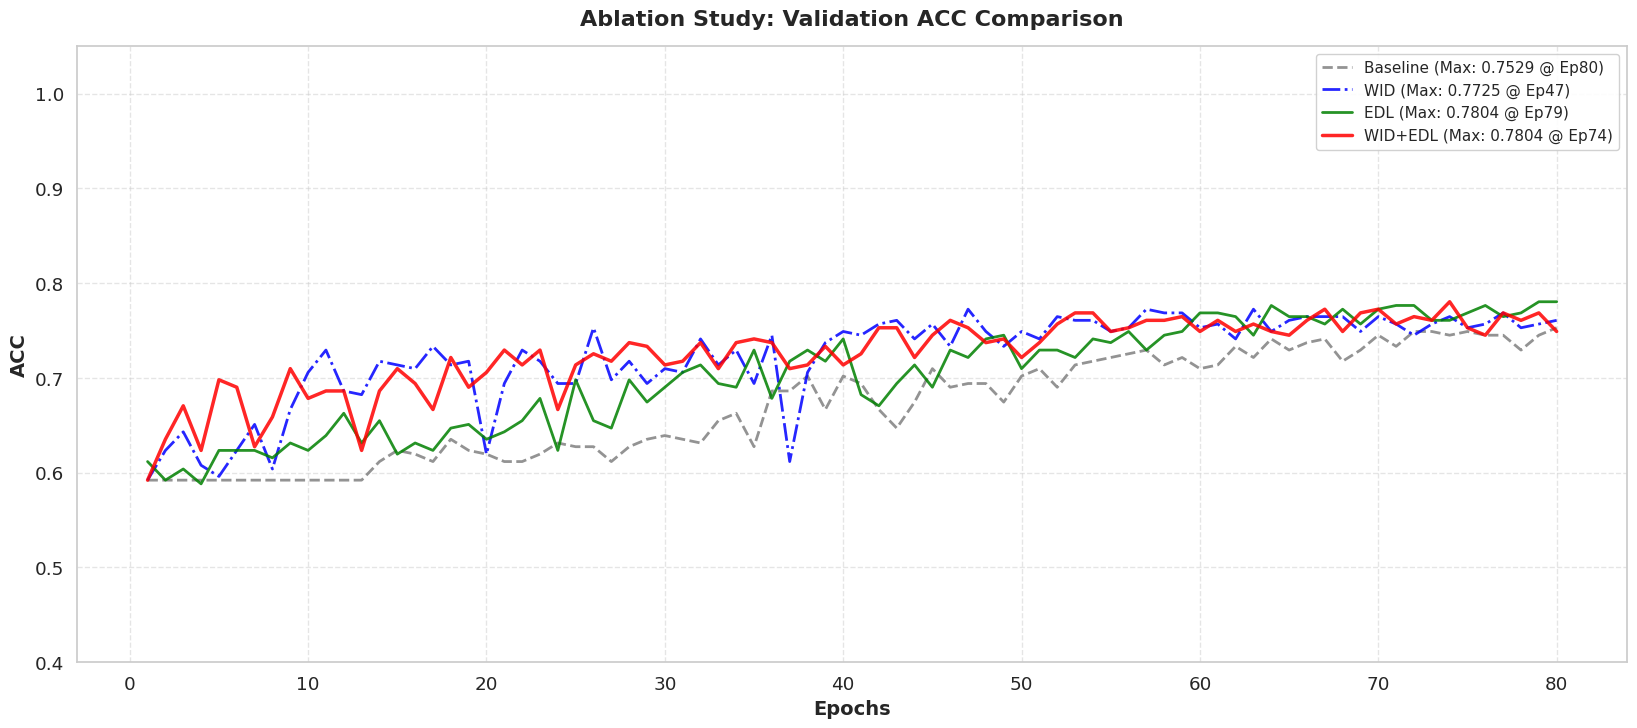

==================== Plotting Combined BCE (val) ====================
Loaded Baseline: Last bce=0.5225, Best=0.5132
Loaded WID: Last bce=0.5194, Best=0.5162
Loaded EDL: Last bce=0.4952, Best=0.4926
Loaded WID+EDL: Last bce=0.5391, Best=0.5158

Figure saved to: ./figures/MIMIC/0216_vgg16/Pneumonia/combined_val_bce.png



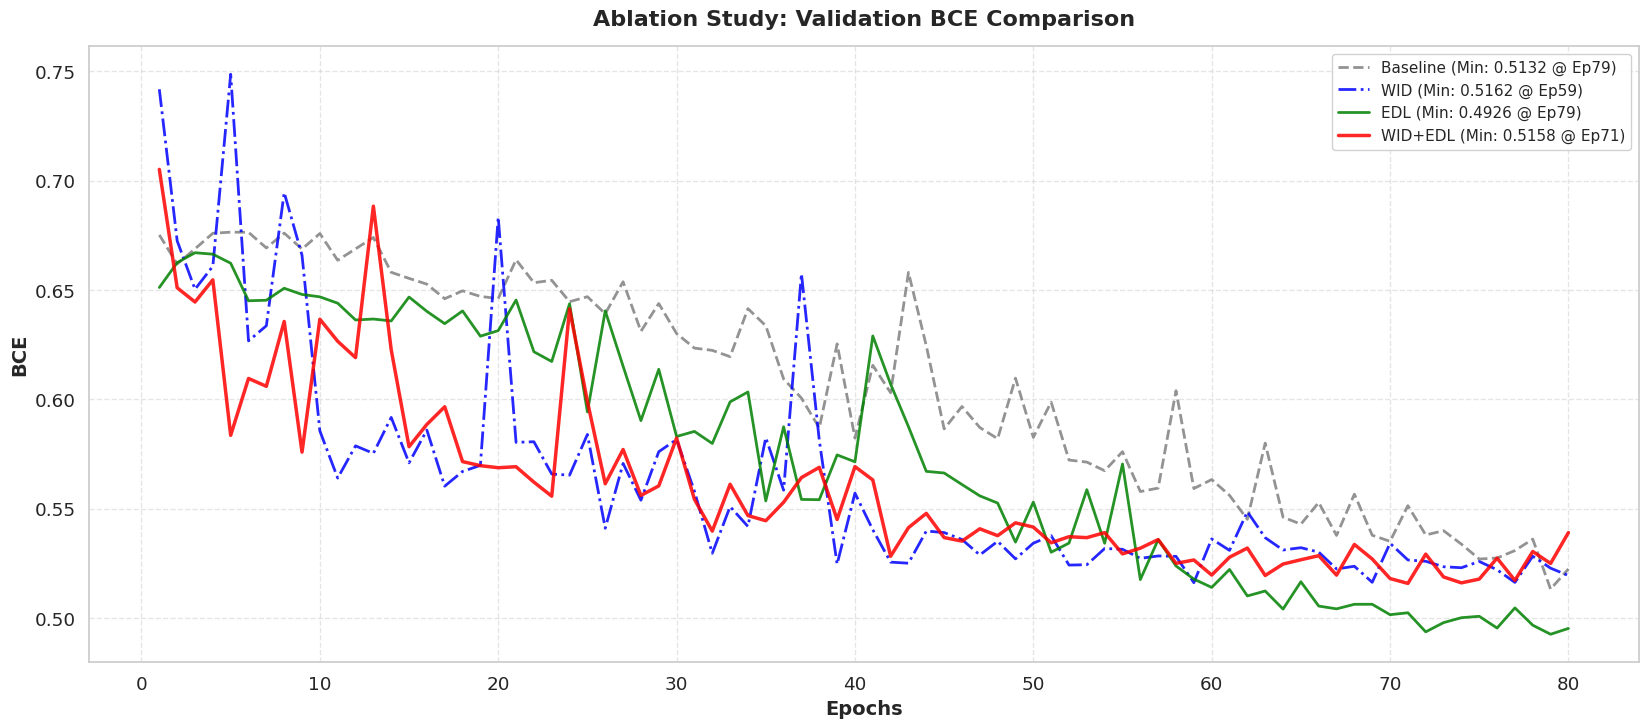

In [3]:
dataset_name = 'MIMIC'
subset_name = 'val'
class_name = 'Pneumonia'
model_configs = {
    'Baseline': {
        'path': f'../result/{dataset_name}/0216_{class_name.replace(" ", "_")}_vgg16_wd0_0001_gc1_0_vw1_0_lm_bce_lr_0.0005_kllmd_0.1_imgdec_0/history.npy',
        'color': 'gray',
        'style': '--',
        'linewidth': 2
    },
    'WID': {
        'path': f'../result/{dataset_name}/0216_{class_name.replace(" ", "_")}_vgg16_wd0_0001_gc1_0_vw1_0_lm_bce_lr_0.0005_kllmd_0.1_imgdec_1/history.npy',
        'color': 'blue',
        'style': '-.',
        'linewidth': 2
    },
    'EDL': {
        'path': f'../result/{dataset_name}/0216_{class_name.replace(" ", "_")}_vgg16_wd0_0001_gc1_0_vw1_0_lm_bcevar_lr_0.0005_kllmd_0.1_imgdec_0/history.npy',
        'color': 'green',
        'style': '-',
        'linewidth': 2
    },
    'WID+EDL': {  # 这是你最新的模型
        'path': f'../result/{dataset_name}/0216_{class_name.replace(" ", "_")}_vgg16_wd0_0001_gc1_0_vw1_0_lm_bcevar_lr_0.0005_kllmd_0.1_imgdec_1/history.npy',
        'color': 'red',
        'style': '-',
        'linewidth': 2.5  # 突出显示自己的模型
    }
}

# 1. 绘制验证集对比 (通常论文里放这个)
plot_combined_history(
    model_configs, 
    metrics=['auc', 'acc', 'bce'], # 你想看哪些指标
    mode=subset_name, 
    save_dir= f'./figures/{dataset_name}/0216_vgg16/{class_name}/'
)